# Import and predefining

In [204]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn import set_config
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms

set_config(display="text")

random_state = 42

torch.manual_seed(random_state)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [205]:
from dataclasses import dataclass


@dataclass
class ModelResult:
    name: str
    confusion_matrix: np.ndarray
    accuracy_score: float

    def __sub__(self, other) -> 'ModelResult':
        if type(other) != type(self):
            raise NotImplementedError

        model_result = ModelResult(
            name=self.name + other.name,
            confusion_matrix=self.confusion_matrix - other.confusion_matrix,
            accuracy_score=self.accuracy_score - other.accuracy_score
        )
        return model_result

In [206]:
def plot_heatmap(
    dataframe: pd.DataFrame | np.ndarray,
    figsize: tuple[int, int] = (6, 5),
    cmap: str | None = None,
    vmin: float | None = None,
    vmax: float | None = None,
    rotation: int = 45,
    xticklabels: list[str] | bool = True,
    yticklabels: list[str] | bool = True,
    title_name: str | None = None,
    ax: plt.Axes | None = None, # pyright: ignore[reportPrivateImportUsage]
) -> None:
    if ax is None:
        plt.figure(figsize=figsize)

    sns.heatmap(
        dataframe,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        linewidths=0.5,
        annot=True,
        fmt=".2f",
        annot_kws={"size": 7},
        xticklabels=xticklabels,
        yticklabels=yticklabels,
        ax=ax,
    )

    if ax is None:
        plt.xticks(rotation=rotation, ha="right", fontsize=9)
        plt.yticks(rotation=0, fontsize=9)
        if title_name:
            plt.title(title_name)
        plt.show()
    else:
        ax.tick_params(axis="x", rotation=rotation, labelsize=9)
        ax.tick_params(axis="y", rotation=0, labelsize=9)
        if title_name:
            ax.set_title(title_name)

def plot_table(
        cellText: np.ndarray | pd.DataFrame,
        rowLabels: list | None = None,
        colLabels: list | None = None,
        title_name: str | None = None,
        fontsize: int = 10,
        scale: tuple[float, float] = (1.7, 1.5),
        figsize: tuple[int, int] = (8, 3)
    ) -> None:
    fig, ax = plt.subplots(figsize=figsize)
    ax.axis('off')

    table = ax.table(
        cellText=cellText,
        rowLabels=rowLabels,
        colLabels=colLabels,
        cellLoc='center',
        loc='center'
    )

    table.auto_set_font_size(False)
    table.set_fontsize(fontsize)
    table.scale(*scale)
    if title_name:
        plt.title(title_name)
    plt.show()

# 1. Повнозв'язані нейронні мережі
1. Візьміть датасет, з яким ви працювали в лабораторній роботі №1.
1. Побудуйте повнозв'язану нейронну мережу (MLP) для задачі класифікації.
1. Навчіть модель на тренувальній вибірці та оцініть її якість на тестовій.
1. Побудуйте learning curves (train/validation loss) та проаналізуйте процес навчання моделі. Чи спостерігається перенавчання?
1. Порівняйте результати нейронної мережі з результатами класичних алгоритмів машинного навчання з Lab 1.
1. Зробіть висновки.

## Візьміть датасет, з яким ви працювали в лабораторній роботі №1

In [207]:
label_encoder_lab_1 = LabelEncoder()
scaler = StandardScaler()
datapath_lab_1 = Path("../lab1/data/Date_Fruit_Datasets.xlsx")
raw_data_lab_1 = pd.read_excel(datapath_lab_1)

target_name = "Class"
features_lab_1 = raw_data_lab_1.drop(target_name, axis=1)
target_lab_1 = raw_data_lab_1[target_name]

target_encoded_lab_1 = label_encoder_lab_1.fit_transform(target_lab_1)

X_train_lab_1, X_test_lab_1, y_train_lab_1, y_test_lab_1  = train_test_split(features_lab_1, target_encoded_lab_1, random_state=random_state, test_size=0.25, stratify=target_encoded_lab_1)

X_train_lab_1_scaled = scaler.fit_transform(X_train_lab_1)
X_test_lab_1_scaled = scaler.transform(X_test_lab_1)

In [208]:
X_train_lab_1_scaled.shape, X_test_lab_1_scaled.shape, y_train_lab_1.shape, y_test_lab_1.shape

((673, 34), (225, 34), (673,), (225,))

In [209]:
len(label_encoder_lab_1.classes_)

7

## Побудуйте повнозв'язану нейронну мережу (MLP) для задачі класифікації

In [210]:
class MLP(nn.Module):
    def __init__(self, in_features: int, out_features: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, out_features)   # logits
        )

    def forward(self, x):
        logits = self.net(x)  # [B, 34] -> [B, 7]
        return logits  # [B, 7]

in_features = X_train_lab_1_scaled.shape[-1]
out_features = len(label_encoder_lab_1.classes_)
model = MLP(in_features, out_features).to(device)
print(model)

MLP(
  (net): Sequential(
    (0): Linear(in_features=34, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=7, bias=True)
  )
)


## Навчіть модель на тренувальній вибірці та оцініть її якість на тестовій

In [ ]:
model = MLP(in_features, out_features).to(device)

num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Trainable params:", num_params)
print()

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-3)

patience = 10
n_epochs = 100
best_model_path = "best_model.pth"
batch_size = 32

X_not_test_t = torch.as_tensor(X_train_lab_1_scaled, dtype=torch.float32)
y_not_test_t = torch.as_tensor(y_train_lab_1, dtype=torch.long)

X_train_t, X_val_t, y_train_t, y_val_t = train_test_split(X_not_test_t, y_not_test_t, test_size=0.1, stratify=y_not_test_t, random_state=random_state)

train_loader = DataLoader(TensorDataset(X_train_t.to(device), y_train_t.to(device)), batch_size=batch_size, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_t.to(device), y_val_t.to(device)), batch_size=batch_size, shuffle=False)

X_train_len = len(X_train_t)
X_val_len = len(X_val_t)

def train_and_eval(model, criterion, optimizer, patience: int, n_epochs: int, best_model_path: str, X_train_len, X_val_len, train_loader, val_loader) -> tuple[list[float], list[float], list[float], list[float]]:
    best_val_loss = float('inf')
    epochs_no_improve = 0
    train_loss_history: list[float] = []
    train_accuracy_history: list[float] = []
    val_loss_history: list[float] = []
    val_accuracy_history: list[float] = []
    for epoch in range(n_epochs):
    # --- train ---
        model.train()
        train_loss = 0.0
        train_accuracy = 0.0
        for x, y in train_loader:
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            train_accuracy += (out.argmax(dim=1) == y).sum().item()
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * x.size(0)
        train_loss /= X_train_len
        train_accuracy /= X_train_len

    # --- validation ---
        model.eval()
        val_loss = 0.0
        val_accuracy = 0.0
        with torch.no_grad():
            for x, y in val_loader:
                out = model(x)
                loss = criterion(out, y)
                val_accuracy += (out.argmax(dim=1) == y).sum().item()
                val_loss += loss.item() * x.size(0)
        val_loss /= X_val_len
        val_accuracy /= X_val_len

        train_loss_history.append(train_loss)
        train_accuracy_history.append(train_accuracy)
        val_loss_history.append(val_loss)
        val_accuracy_history.append(val_accuracy)
        print(f"[{epoch+1:02d}] train_loss={train_loss:.4f} | train_accuracy={train_accuracy:.4f} | val_loss={val_loss:.4f} | val_accuracy={val_accuracy:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            epochs_no_improve = 0
            torch.save(model.state_dict(), best_model_path)
            print("Saved best model")
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print("Early stopping epoch: ", epoch)
                break

    return train_loss_history, train_accuracy_history, val_loss_history, val_accuracy_history

train_loss_history, train_accuracy_history, val_loss_history, val_accuracy_history = train_and_eval(model, criterion, optimizer, patience, n_epochs, best_model_path, X_train_len, X_val_len, train_loader, val_loader)

Trainable params: 13191

[01] train_loss=1.6190 | train_accuracy=0.5603 | val_loss=1.1772 | val_accuracy=0.6912
Saved best model
[02] train_loss=0.9781 | train_accuracy=0.6975 | val_loss=0.7089 | val_accuracy=0.7206
Saved best model
[03] train_loss=0.6458 | train_accuracy=0.7620 | val_loss=0.5237 | val_accuracy=0.7941
Saved best model
[04] train_loss=0.4822 | train_accuracy=0.8165 | val_loss=0.4362 | val_accuracy=0.8088
Saved best model
[05] train_loss=0.4093 | train_accuracy=0.8529 | val_loss=0.3869 | val_accuracy=0.8235
Saved best model
[06] train_loss=0.3541 | train_accuracy=0.8826 | val_loss=0.3495 | val_accuracy=0.8382
Saved best model
[07] train_loss=0.3213 | train_accuracy=0.8926 | val_loss=0.3011 | val_accuracy=0.8676
Saved best model
[08] train_loss=0.2995 | train_accuracy=0.9008 | val_loss=0.2878 | val_accuracy=0.8824
Saved best model
[09] train_loss=0.2731 | train_accuracy=0.9091 | val_loss=0.2597 | val_accuracy=0.8971
Saved best model
[10] train_loss=0.2567 | train_accuracy

[25] train_loss=0.1308 | train_accuracy=0.9504 | val_loss=0.1489 | val_accuracy=0.9412
[26] train_loss=0.1174 | train_accuracy=0.9636 | val_loss=0.1358 | val_accuracy=0.9559
Saved best model
[27] train_loss=0.1164 | train_accuracy=0.9554 | val_loss=0.1324 | val_accuracy=0.9559
Saved best model
[28] train_loss=0.1093 | train_accuracy=0.9653 | val_loss=0.1686 | val_accuracy=0.9412
[29] train_loss=0.1223 | train_accuracy=0.9587 | val_loss=0.1494 | val_accuracy=0.9559
[30] train_loss=0.1147 | train_accuracy=0.9587 | val_loss=0.1449 | val_accuracy=0.9559
[31] train_loss=0.1041 | train_accuracy=0.9620 | val_loss=0.1370 | val_accuracy=0.9559
[32] train_loss=0.0964 | train_accuracy=0.9653 | val_loss=0.1318 | val_accuracy=0.9559
Saved best model
[33] train_loss=0.0947 | train_accuracy=0.9719 | val_loss=0.1429 | val_accuracy=0.9412
[34] train_loss=0.0985 | train_accuracy=0.9603 | val_loss=0.1312 | val_accuracy=0.9559
Saved best model
[35] train_loss=0.0926 | train_accuracy=0.9669 | val_loss=0.15

## Побудуйте learning curves (train/validation loss) та проаналізуйте процес навчання моделі. Чи спостерігається перенавчання?

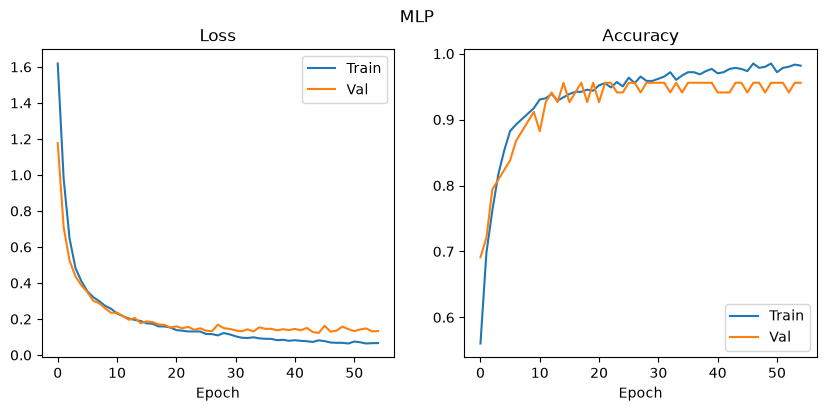

In [ ]:
def plot_learning_curves(train_loss_history: list[float], train_accuracy_history: list[float], val_loss_history: list[float], val_accuracy_history: list[float], title: str):
    fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(10, 4))

    sns.lineplot(train_loss_history, label="Train", ax=ax1)
    sns.lineplot(val_loss_history, label="Val", ax=ax1)

    sns.lineplot(train_accuracy_history, label="Train", ax=ax2)
    sns.lineplot(val_accuracy_history, label="Val", ax=ax2)

    ax1.set_title("Loss")
    ax1.set_xlabel("Epoch")

    ax2.set_title("Accuracy")
    ax2.set_xlabel("Epoch")

    plt.suptitle(title)
    plt.show()

plot_learning_curves(train_loss_history, train_accuracy_history, val_loss_history, val_accuracy_history, title="MLP")

Спостерігається перенавчання починаючи з епохи 46 і до 54, де зупиняється через ранню зупинку.

## Порівняйте результати нейронної мережі з результатами класичних алгоритмів машинного навчання з Lab 1

In [213]:
pca_svc = Pipeline([
    ('pca', PCA(n_components=9, random_state=random_state)),
    ('svc', SVC(C=10, gamma = 0.01, kernel = 'rbf', random_state=random_state))
])
pca_svc.fit(X_train_t.detach().numpy(), y_train_t.detach().numpy())
old_pred = pca_svc.predict(X_test_lab_1_scaled)

In [214]:
model.load_state_dict(torch.load(best_model_path, weights_only=True))

X_test_t = torch.as_tensor(X_test_lab_1_scaled, dtype=torch.float32, device=device)
y_test_t = torch.as_tensor(y_test_lab_1, dtype=torch.long, device=device)

model.eval()
with torch.no_grad():
    y_pred = model(X_test_t).argmax(dim=1).cpu().numpy()

labels = label_encoder_lab_1.classes_

mlp_score = accuracy_score(y_test_lab_1, y_pred)
print(f"MLP Test accuracy: {mlp_score:.4f}")
mlp_report = classification_report(y_test_lab_1, y_pred, target_names=labels)
print(mlp_report)

svc_score = accuracy_score(y_test_lab_1, old_pred)
print(f"SVC Test accuracy: {svc_score:.4f}")
svc_report = classification_report(y_test_lab_1, old_pred, target_names=labels)
print(svc_report)

MLP Test accuracy: 0.9467
              precision    recall  f1-score   support

       BERHI       1.00      0.94      0.97        16
      DEGLET       0.84      0.84      0.84        25
       DOKOL       0.98      0.96      0.97        51
       IRAQI       0.95      1.00      0.97        18
      ROTANA       0.93      0.98      0.95        42
      SAFAVI       0.96      1.00      0.98        50
       SOGAY       0.95      0.83      0.88        23

    accuracy                           0.95       225
   macro avg       0.94      0.93      0.94       225
weighted avg       0.95      0.95      0.95       225

SVC Test accuracy: 0.9422
              precision    recall  f1-score   support

       BERHI       1.00      0.88      0.93        16
      DEGLET       0.91      0.80      0.85        25
       DOKOL       0.96      0.98      0.97        51
       IRAQI       0.90      1.00      0.95        18
      ROTANA       0.98      0.95      0.96        42
      SAFAVI       0.96   

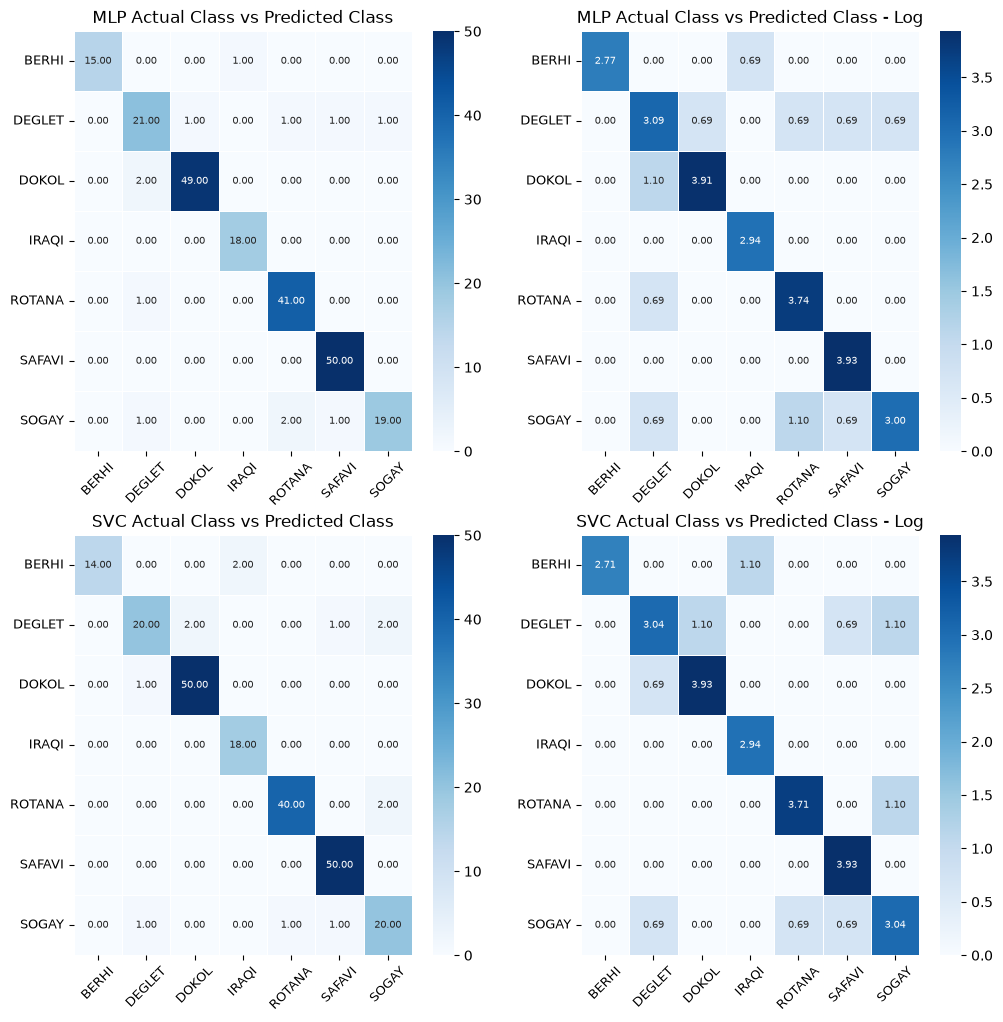

In [215]:
conf_matrx = confusion_matrix(y_test_lab_1, y_pred)
old_conf_matrx = confusion_matrix(y_test_lab_1, old_pred)

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(nrows=2, ncols=2, figsize=(12, 12))
figsize_heatmap = (6, 5)
plot_heatmap(
    dataframe=conf_matrx,
    figsize=figsize_heatmap,
    xticklabels=labels, yticklabels=labels, # pyright: ignore[reportArgumentType]
    cmap="Blues",
    title_name="MLP Actual Class vs Predicted Class",
    ax=ax1
)
plot_heatmap(
    dataframe=np.log1p(conf_matrx),
    figsize=figsize_heatmap,
    xticklabels=labels, yticklabels=labels, # pyright: ignore[reportArgumentType]
    cmap="Blues",
    title_name="MLP Actual Class vs Predicted Class - Log",
    ax=ax2
)
plot_heatmap(
    dataframe=old_conf_matrx,
    figsize=figsize_heatmap,
    xticklabels=labels, yticklabels=labels, # pyright: ignore[reportArgumentType]
    cmap="Blues",
    title_name="SVC Actual Class vs Predicted Class",
    ax=ax3
)
plot_heatmap(
    dataframe=np.log1p(old_conf_matrx),
    figsize=figsize_heatmap,
    xticklabels=labels, yticklabels=labels, # pyright: ignore[reportArgumentType]
    cmap="Blues",
    title_name="SVC Actual Class vs Predicted Class - Log",
    ax=ax4
)

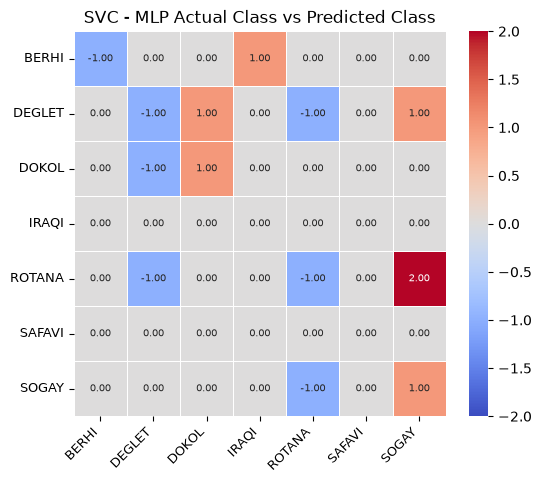

In [216]:

svc_model_result = ModelResult(
    name="SVC",
    confusion_matrix=old_conf_matrx,
    accuracy_score=svc_score # pyright: ignore[reportArgumentType]
)


mlp_model_result = ModelResult(
    name="MLP",
    confusion_matrix=conf_matrx,
    accuracy_score=mlp_score # pyright: ignore[reportArgumentType]
)

diff_model_result = svc_model_result - mlp_model_result

figsize_heatmap = (6, 5)
plot_heatmap(
    dataframe=diff_model_result.confusion_matrix,
    figsize=figsize_heatmap,
    xticklabels=labels, yticklabels=labels, # pyright: ignore[reportArgumentType]
    cmap="coolwarm",
    title_name="SVC - MLP Actual Class vs Predicted Class",
    vmin=-2, vmax=2
)

## Зробіть висновки

Повнозв'язна нейронна мережа на стандартизованих ознаках досягла тестової точності 0.9467 та макросереднього F1 на рівні 0.94, порівняно з `SVC` із точністю 0.9422 та макросереднім F1 на рівні 0.93 випереджає на один тестовий об'єкт із 225 за однакового обсягу навчальних даних.

Використання окремої валідаційної вибірки, L2-регуляризації та ранньої зупинки дозволило вчасно зафіксувати ваги моделі до початку сильного перенавчання на малій вибірці та отримати об'єктивну оцінку якості на ізольованих тестових даних.

`MLP` без помилок розпізнає всі тестові зразки сортів `'IRAQI'` та `'SAFAVI'`, досягаючи повної чутливості 1.00.
Порівняно з `SVC`, нейромережа точніше класифікує сорти `'BERHI'`, `'DEGLET'` та `'ROTANA'` із перевагою в один об'єкт на кожному класі.
Метод опорних векторів випереджає `MLP` на один приклад у класах `'DOKOL'` та `'SOGAY'`.
Основна частка хибних спрацювань в обох моделей виникає між подібними за ознаками сортами `'DEGLET'`, `'DOKOL'`, `'ROTANA'` та `'SOGAY'`.

# 2. Згорткові нейронні мережі
1. Оберіть датасет зображень для задачі класифікації. 
1. Коротко опишіть датасет (класи, кількість зображень) та візуалізуйте приклади зображень для кожного класу. 
1. Вирішіть задачу класифікації двома способами.
    1. a)
        1. Побудуйте просту CNN (2–3 convolutional шари + fully connected layer).
        1. Навчіть модель на обраному датасеті.
        1. Побудуйте learning curves (train/validation loss) та проаналізуйте процес навчання.
    1. b) 
        1. Використайте попередньо натреновану модель (наприклад, ResNet, EfficientNet, MobileNet або іншу pretrained CNN).
        1. Замініть вихідний класифікатор відповідно до кількості класів вашого датасету та проведіть донавчання моделі.
1. Порівняйте CNN, навчену з нуля, та pretrained модель:  якість класифікації;  процес і швидкість збіжності;  learning curves;  вплив обсягу тренувальних даних.
1. Зробіть висновки.

## Оберіть датасет зображень для задачі класифікації

In [ ]:

datapath = Path("../lab3/data/")
random_state = 42

train_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
])

eval_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
])

train_full = datasets.ImageFolder(datapath / "train", transform=train_transform)
val_full = datasets.ImageFolder(datapath / "train", transform=eval_transform)
test_dataset = datasets.ImageFolder(datapath / "test", transform=eval_transform)

img_labels_str = train_full.classes
targets = np.array(train_full.targets)
img_labels = np.unique(targets)

train_idx, val_idx = train_test_split(
    np.arange(len(targets)),
    test_size=0.25,
    random_state=random_state,
    stratify=targets,
)

train_dataset = Subset(train_full, train_idx)
val_dataset = Subset(val_full, val_idx)

NameError: name 'Subset' is not defined

In [ ]:
from sklearn.datasets import load_files

label_encoder = LabelEncoder()
datapath = Path("../lab3/data/")

train_bundle = load_files(datapath / "train", load_content=False, shuffle=False)
test_bundle = load_files(datapath / "test", load_content=False, shuffle=False)

labels_str = np.unique(Y)
y = label_encoder.fit_transform(Y)
labels = np.unique(y)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    random_state=random_state,
    test_size=0.25,
    stratify=labels,
)

## Коротко опишіть датасет (класи, кількість зображень) та візуалізуйте приклади зображень для кожного класу

## Вирішіть задачу класифікації двома способами

### a)

#### Побудуйте просту CNN (2–3 convolutional шари + fully connected layer)

#### Навчіть модель на обраному датасеті

#### Побудуйте learning curves (train/validation loss) та проаналізуйте процес навчання

### b)

#### Використайте попередньо натреновану модель (наприклад, ResNet, EfficientNet, MobileNet або іншу pretrained CNN)

#### Замініть вихідний класифікатор відповідно до кількості класів вашого датасету та проведіть донавчання моделі

## Порівняйте CNN, навчену з нуля, та pretrained модель:  якість класифікації;  процес і швидкість збіжності;  learning curves;  вплив обсягу тренувальних даних

## Зробіть висновки

# 3. Нейронні мережі для класифікації текстів
1. Використайте той самий текстовий датасет, з яким ви працювали в лабораторній роботі №2.
1. Проведіть необхідну передобробку текстових даних: токенізацію, побудову словника, перетворення токенів в індекси та приведення послідовностей до однакової довжини (padding/truncation).
1. Вирішіть задачу класифікації двома способами.
1. 
    1. а)
        1. Побудуйте модель з Embedding layer, ініціалізованим випадковими вагами.
        1. Використайте RNN / LSTM / GRU для класифікації та навчіть модель на своєму датасеті.
    1. б)
        1. Завантажте готові pretrained embeddings (наприклад, GloVe) та ініціалізуйте ними Embedding layer.
        1. Проведіть навчання моделі.
1. Для обох моделей побудуйте learning curves (train/validation loss).
1. Порівняйте результати двох підходів:  якість класифікації;  швидкість і стабільність навчання;  вплив pretrained embeddings на отриманий результат.
1. Зробіть висновки.

## Використайте той самий текстовий датасет, з яким ви працювали в лабораторній роботі №2

In [ ]:
import re

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

datapath_lab_2 = Path("../lab2/data/train.csv")
raw_data_lab_2 = pd.read_csv(datapath_lab_2)

raw_texts = raw_data_lab_2["text"]
targets = raw_data_lab_2["model"]
text_labels = np.sort(targets.unique())

raw_train, raw_test, targets_train, targets_test = train_test_split(
    raw_texts,
    targets,
    random_state=random_state,
    test_size=0.15,
    stratify=targets,
)

## Проведіть необхідну передобробку текстових даних: токенізацію, побудову словника, перетворення токенів в індекси та приведення послідовностей до однакової довжини (padding/truncation)

In [ ]:
def extract_style_features(texts: pd.Series) -> np.ndarray:
    feats = []
    for text in texts:
        length = max(len(text), 1)
        words = text.split()
        n_words = max(len(words), 1)
        sentences = [s for s in re.split(r"[.!?]+", text) if s.strip()]
        n_sents = max(len(sentences), 1)

        feats.append([
            np.log1p(length),                                                 # total character length
            np.log1p(n_words),                                                # total word count
            length / n_words,                                                 # average word length
            n_words / n_sents,                                                # average sentence length (rhythm)
            text.count(",") / n_words,                                        # comma density (clause complexity)
            text.count(";") / n_words,                                        # semicolon usage
            text.count(":") / n_words,                                        # colon usage
            text.count("—") / n_words,                                        # em-dash usage
            text.count(" — ") / n_words,                                      # em-dash usage
            (text.count("’") + text.count("“") + text.count("”")) / n_words,  # curly quotes
            (text.count("'") + text.count('"')) / n_words,                    # straight quotes
            sum(c.isupper() for c in text) / length,                          # uppercase ratio
            sum(c.isdigit() for c in text) / length,                          # digit ratio
        ])
    return np.array(feats, dtype=np.float32)


vectorizer = FeatureUnion(
    transformer_list=[
        ("word", TfidfVectorizer(
            lowercase=False,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True,
            token_pattern=r"\S+",
        )),
        ("char", TfidfVectorizer(
            lowercase=False,
            analyzer="char",
            ngram_range=(3, 5),
            min_df=5,
            max_df=0.95,
            sublinear_tf=True,
        )),
        ("style", Pipeline([
            ("extract", FunctionTransformer(extract_style_features, validate=False)),
            ("scale", StandardScaler()),
        ])),
    ], # type: ignore
    transformer_weights={"word": 1.0, "char": 1.0, "style": 0.25},
)

## Вирішіть задачу класифікації двома способами

### a)

#### Побудуйте модель з Embedding layer, ініціалізованим випадковими вагами

#### Використайте RNN / LSTM / GRU для класифікації та навчіть модель на своєму датасеті

In [ ]:
pipe_RNN = Pipeline([
    ("vec", vectorizer),
    ("clf", LogisticRegression(max_iter=1000, random_state=random_state)),
])

pipe_LSTM = Pipeline([
    ("vec", vectorizer),
    ("clf", LogisticRegression(max_iter=1000, random_state=random_state)),
])

pipe_GRU = Pipeline([
    ("vec", vectorizer),
    ("clf", LogisticRegression(max_iter=1000, random_state=random_state)),
])

NameError: name 'Pipeline' is not defined

### b)

#### Завантажте готові pretrained embeddings (наприклад, GloVe) та ініціалізуйте ними Embedding layer

#### Проведіть навчання моделі

## Для обох моделей побудуйте learning curves (train/validation loss)

## Порівняйте результати двох підходів:  якість класифікації;  швидкість і стабільність навчання;  вплив pretrained embeddings на отриманий результат

## Зробіть висновки